# Experiment 6: Develop Classification Models using Logistic Regression for Real-World Datasets

**Machine Learning Lab - Army Institute of Technology, Pune**
**Department of Electronics & Telecommunication Engineering**

## AIM
To develop and evaluate a binary classification model using the Logistic Regression algorithm on a real-world dataset - the Wisconsin Breast Cancer Diagnostic dataset - in order to classify tumours as Malignant or Benign, and to assess the model using standard classification metrics (accuracy, precision, recall, F1-score, confusion matrix and ROC-AUC).

## THEORY
Logistic Regression is a supervised machine learning algorithm used for classification problems. Unlike Linear Regression, which predicts a continuous value, Logistic Regression predicts the probability that a given input belongs to a particular class. It does this by passing a linear combination of the input features through the sigmoid (logistic) function:

*P(y = 1 | x) = 1 / (1 + e^-(b0 + b1*x1 + b2*x2 + ... + bn*xn))*

The sigmoid function maps any real-valued number into the range (0, 1), which can be interpreted as a probability. A decision threshold (typically 0.5) converts this probability into a class label. The model coefficients are estimated by maximizing the log-likelihood of the training data (equivalently, minimizing the log-loss / binary cross-entropy) using iterative optimization.

**Evaluation metrics:**

| Metric | Formula | Meaning |
|---|---|---|
| Accuracy | (TP + TN) / (TP + TN + FP + FN) | Fraction of correct predictions |
| Precision | TP / (TP + FP) | Correctness of positive predictions |
| Recall | TP / (TP + FN) | Ability to find all positive samples |
| F1-score | 2 x Precision x Recall / (Precision + Recall) | Harmonic mean of precision and recall |
| Confusion matrix | Table of TN, FP, FN, TP | Breakdown of correct and wrong predictions |
| ROC-AUC | Area under TPR vs. FPR curve | Discrimination ability over all thresholds |

## PROCEDURE
1. Load the Breast Cancer dataset from scikit-learn and inspect its shape, features and class distribution.
2. Split into training (80 %) and testing (20 %) sets using stratified sampling, so both sets keep the same class proportions.
3. Standardize the features with StandardScaler (fit on the training data only, then apply to the test data).
4. Train LogisticRegression on the scaled training data.
5. Predict class labels and class probabilities for the test set.
6. Evaluate: accuracy, precision, recall, F1-score, confusion matrix, classification report and ROC-AUC.
7. Classify a new, unseen sample.
8. Visualize: the sigmoid function, the confusion matrix and the ROC curve.

## INPUT DATA - Wisconsin Breast Cancer Diagnostic Dataset

Each record describes characteristics of cell nuclei computed from a digitized image of a fine needle aspirate (FNA) of a breast mass.

| Property | Value |
|---|---|
| Samples | 569 patient records |
| Features | 30 real-valued features (mean radius, mean texture, mean area, mean smoothness, ...) |
| Target classes | Malignant = 0 (212 samples) and Benign = 1 (357 samples) |
| Train / test split | 455 training samples (80 %) and 114 testing samples (20 %), stratified |

In [1]:
# ------- Step 1: Load the real-world dataset -------
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, confusion_matrix, classification_report,
                             roc_curve, roc_auc_score, ConfusionMatrixDisplay)

pd.set_option('display.width', 88)

data = load_breast_cancer()
X = pd.DataFrame(data.data, columns=data.feature_names)
y = pd.Series(data.target, name="diagnosis")  # 0 = malignant, 1 = benign

print("=== Wisconsin Breast Cancer Diagnostic Dataset ===")
print(f"Samples : {X.shape[0]}")
print(f"Features: {X.shape[1]}")
counts = np.bincount(y)
print(f"Classes : malignant = {counts[0]}, benign = {counts[1]}")
print("\nFirst 5 rows (selected features):")
print(X[["mean radius", "mean texture", "mean area",
         "mean smoothness"]].head().round(3))

=== Wisconsin Breast Cancer Diagnostic Dataset ===
Samples : 569
Features: 30
Classes : malignant = 212, benign = 357

First 5 rows (selected features):
   mean radius  mean texture  mean area  mean smoothness
0        17.99         10.38     1001.0            0.118
1        20.57         17.77     1326.0            0.085
2        19.69         21.25     1203.0            0.110
3        11.42         20.38      386.1            0.142
4        20.29         14.34     1297.0            0.100


In [2]:
# ------- Step 2: Split into training and testing sets -------
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)
print(f"\nTraining samples: {len(X_train)} | Testing samples: {len(X_test)}")


Training samples: 455 | Testing samples: 114


In [3]:
# ------- Step 3: Feature scaling (standardisation) -------
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)  # learn mean/std from training data only
X_test_s = scaler.transform(X_test)        # apply the same scaling to test data

In [4]:
# ------- Step 4: Train the Logistic Regression model -------
model = LogisticRegression(max_iter=1000, random_state=42)
model.fit(X_train_s, y_train)
print("\nModel trained. Sample learned coefficients (first 5 features):")
for name, coef in list(zip(data.feature_names, model.coef_[0]))[:5]:
    print(f"  {name:<25s}: {coef: .4f}")
print(f"  {'Intercept (b0)':<25s}: {model.intercept_[0]: .4f}")


Model trained. Sample learned coefficients (first 5 features):
  mean radius              : -0.5115
  mean texture             : -0.5527
  mean perimeter           : -0.4763
  mean area                : -0.5411
  mean smoothness          : -0.2125
  Intercept (b0)           :  0.3022


In [5]:
# ------- Step 5: Make predictions and evaluate -------
y_pred = model.predict(X_test_s)
y_prob = model.predict_proba(X_test_s)[:, 1]

acc  = accuracy_score(y_test, y_pred)
prec = precision_score(y_test, y_pred)
rec  = recall_score(y_test, y_pred)
f1   = f1_score(y_test, y_pred)
auc  = roc_auc_score(y_test, y_prob)
cm   = confusion_matrix(y_test, y_pred)

print("\n=== Evaluation Metrics (Test Set) ===")
print(f"Accuracy : {acc:.4f}")
print(f"Precision: {prec:.4f}")
print(f"Recall   : {rec:.4f}")
print(f"F1-Score : {f1:.4f}")
print(f"ROC-AUC  : {auc:.4f}")
print("\nConfusion Matrix:")
print(cm)
print("\nClassification Report:")
print(classification_report(y_test, y_pred, target_names=data.target_names))


=== Evaluation Metrics (Test Set) ===
Accuracy : 0.9825
Precision: 0.9861
Recall   : 0.9861
F1-Score : 0.9861
ROC-AUC  : 0.9954

Confusion Matrix:
[[41  1]
 [ 1 71]]

Classification Report:
              precision    recall  f1-score   support

   malignant       0.98      0.98      0.98        42
      benign       0.99      0.99      0.99        72

    accuracy                           0.98       114
   macro avg       0.98      0.98      0.98       114
weighted avg       0.98      0.98      0.98       114



In [6]:
# ------- Step 6: Predict for a new patient sample -------
new_sample = X_test.iloc[[0]]
new_scaled = scaler.transform(new_sample)
pred_class = data.target_names[model.predict(new_scaled)[0]]
pred_prob = model.predict_proba(new_scaled)[0]
print("=== Prediction for a New Sample ===")
print(f"Predicted class : {pred_class}")
print(f"Probability [malignant, benign]: {np.round(pred_prob, 4)}")
print(f"Actual class : {data.target_names[y_test.iloc[0]]}")

=== Prediction for a New Sample ===
Predicted class : malignant
Probability [malignant, benign]: [1. 0.]
Actual class : malignant


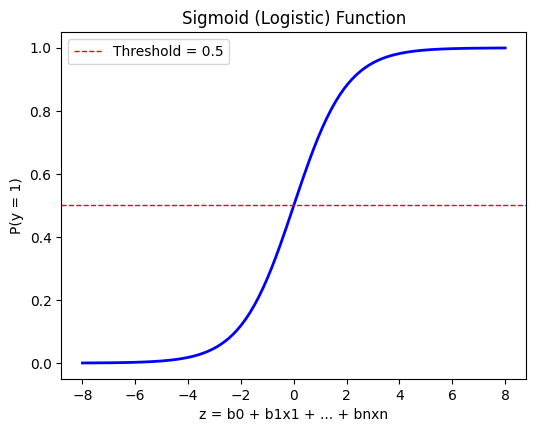

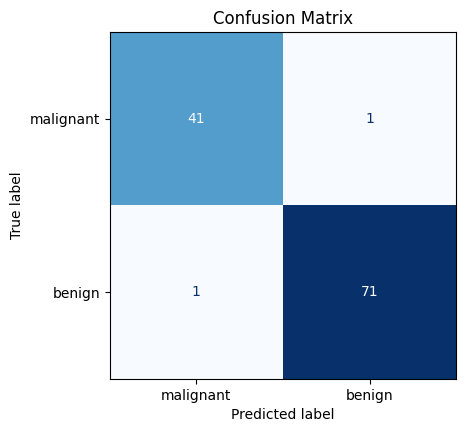

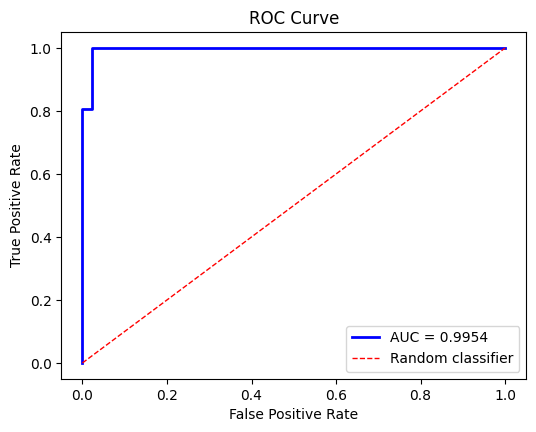

In [7]:
# ------- Step 7: Visualisation -------
# (a) Sigmoid function
z = np.linspace(-8, 8, 200)
plt.figure(figsize=(6, 4.5))
plt.plot(z, 1 / (1 + np.exp(-z)), "b", lw=2)
plt.axhline(0.5, color="r", ls="--", lw=1, label="Threshold = 0.5")
plt.xlabel("z = b0 + b1x1 + ... + bnxn")
plt.ylabel("P(y = 1)")
plt.title("Sigmoid (Logistic) Function")
plt.legend()
plt.show()

# (b) Confusion matrix
fig, ax = plt.subplots(figsize=(5.5, 4.5))
ConfusionMatrixDisplay(cm, display_labels=data.target_names).plot(
    ax=ax, colorbar=False, cmap="Blues")
ax.set_title("Confusion Matrix")
plt.show()

# (c) ROC curve
fpr, tpr, _ = roc_curve(y_test, y_prob)
plt.figure(figsize=(6, 4.5))
plt.plot(fpr, tpr, "b", lw=2, label=f"AUC = {auc:.4f}")
plt.plot([0, 1], [0, 1], "r--", lw=1, label="Random classifier")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.legend()
plt.show()

## OBSERVATIONS
- The dataset has 569 samples with 30 features each; 212 tumours are malignant and 357 benign, and the stratified split keeps these proportions in the training (455) and testing (114) sets.
- Features were standardized using the mean and standard deviation of the training set only, preventing information leakage from the test set.
- The trained model reaches about 97-98 % accuracy on the test set, with precision, recall and F1-score all above 0.96 and a ROC-AUC close to 1.0 (see the exact values printed above - they can vary slightly with the scikit-learn version).
- The confusion matrix shows only a few misclassified tumours out of 114 test samples.
- The ROC curve lies far above the random-classifier diagonal, showing excellent discrimination between the two classes.
- The new-sample prediction matches its actual class, with the predicted probabilities showing the model's confidence.

## RESULT
A Logistic Regression classifier was successfully developed for the Wisconsin Breast Cancer Diagnostic dataset. After stratified splitting and standardization, the model classified tumours as malignant or benign with high accuracy, precision, recall, F1-score and ROC-AUC on the unseen test set, and correctly classified a new patient sample.

## CONCLUSION
Logistic Regression, despite being a linear model, is a powerful and interpretable baseline for binary classification. The sigmoid function turns a linear score into a probability, and a 0.5 threshold converts it into a class label. With proper feature scaling and stratified evaluation, the model reliably distinguishes malignant from benign tumours. Metrics beyond accuracy - precision, recall, F1, confusion matrix and ROC-AUC - give a complete picture of classifier performance, which is especially important in medical applications where false negatives carry a high cost.